# Tạo bộ ảnh banknote từ ZIP gốc

Đọc ảnh và nhãn YOLO trong ZIP, chọn ảnh, áp dụng quyết định review đã chốt, rồi cắt và lưu 377 ảnh train.

Chạy lần lượt từ trên xuống. Kết quả nằm ngoài thư mục `DATA`.


## 1. Chuẩn bị thư viện và thư mục kết quả

Chọn ZIP gốc và tạo thư mục riêng cho lần chạy. Các file CSV trong thư mục kết quả là báo cáo do notebook tạo ra.

In [24]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from collections import Counter
from datetime import datetime
from PIL import Image, ImageOps
from IPython.display import display
import pandas as pd
import numpy as np
import cv2
import yaml
import hashlib
import math
import re
import io
import json
import matplotlib.pyplot as plt


In [25]:
WORK = Path.cwd()
RAW_ZIP = Path.home() / "Downloads" / "Banknotes-Recognition-main.zip"
OUTPUT = Path(r"C:\CS231_BANKNOTES_FROM_RAW\single_notebook_runs") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT.mkdir(parents=True)
TARGET_CLASSES = ["10000", "20000", "50000", "100000", "200000", "500000"]
EXPECTED_COUNTS = {"10000": 65, "20000": 57, "50000": 65,
                   "100000": 66, "200000": 65, "500000": 59}
assert RAW_ZIP.is_file(), f"Không tìm thấy ZIP: {RAW_ZIP}"
raw_zip_hash = hashlib.sha256(RAW_ZIP.read_bytes()).hexdigest()
assert raw_zip_hash == "9226161f8b8b5e2133112459599cdd7bf5f378bb8158f9c879ba2f41ceecdf6c"
archive = ZipFile(RAW_ZIP)
members = set(archive.namelist())
print("ZIP:", RAW_ZIP, "\nKết quả:", OUTPUT)


ZIP: Downloads/Banknotes-Recognition-main.zip 
Kết quả: C:\CS231_BANKNOTES_FROM_RAW\single_notebook_runs\20261025_181449_021158


## 2. Xem ảnh và nhãn trong ZIP

`data.yaml` cho biết class ID tương ứng với mệnh giá. Nhãn YOLO có dạng `class_id tâm_x tâm_y rộng cao`; bốn số sau là tỉ lệ từ 0 đến 1.

In [26]:
config_member = ""
for name in sorted(members):
    if name.endswith("/data.yaml"):
        config_member = name
        break
config = yaml.safe_load(archive.read(config_member).decode("utf-8-sig"))
class_names = config["names"]
class_to_vnd = {}
for class_id in range(len(class_names)):
    class_name = class_names[class_id]
    denomination = re.sub(r"\D", "", class_name)
    class_to_vnd[class_id] = denomination

class_rows = []
for class_id in class_to_vnd:
    class_rows.append({"class_id": class_id,
                       "tên trong ZIP": class_names[class_id],
                       "mệnh giá": class_to_vnd[class_id]})
display(pd.DataFrame(class_rows))

image_members = []
for name in sorted(members):
    is_image = "/images/" in name
    is_picture = Path(name).suffix.lower() in [".jpg", ".jpeg", ".png"]
    if is_image and is_picture:
        image_members.append(name)

def label_for(image_member):
    label_name = image_member.replace("/images/", "/labels/")
    label_name = label_name.rsplit(".", 1)[0] + ".txt"
    return label_name

missing_labels = []
for name in image_members:
    if label_for(name) not in members:
        missing_labels.append(name)
original_splits = Counter()
for name in image_members:
    split_name = name.split("/images/")[0].split("/")[-1]
    original_splits[split_name] += 1
print("Ảnh trong images:", len(image_members), "| Split gốc:", dict(original_splits))
print("Có label:", len(image_members) - len(missing_labels), "| Thiếu label:", len(missing_labels))
assert len(image_members) == 2122 and len(missing_labels) == 4
example = ""
for name in image_members:
    if label_for(name) in members:
        example = name
        break
print("Ví dụ ảnh:", example)
print("YOLO label:", archive.read(label_for(example)).decode().strip())

,class_id,tên trong ZIP,mệnh giá
0,0,10 000 VND,10000
1,1,100 000 VND,100000
2,2,20 000 VND,20000
3,3,200 000 VND,200000
4,4,50 000 VND,50000
5,5,500 000 VND,500000


Ảnh trong images: 2122 | Split gốc: {'test': 275, 'train': 1572, 'valid': 275}
Có label: 2118 | Thiếu label: 4
Ví dụ ảnh: Banknotes-Recognition-main/Dataset_2/test/images/010000_109_png.rf.aa87cf871f82a71cf95464925f143956.jpg
YOLO label: 0 0.5671875 0.41640625 0.853125 0.8328125


## 3. Đọc nhãn và gộp tên ảnh

Đọc từng ảnh, kiểm tra nhãn và kích thước. Các file có cùng tên nguồn, kể cả bản `.rf.<hash>`, được xem là một nhóm; giữ bản hợp lệ có độ phân giải cao hơn.

In [27]:
def source_name(member):
    name = re.sub(r"\.rf\.[0-9a-f]+$", "", Path(member).stem, flags=re.I)
    return re.sub(r"_(jpg|png|jpeg)$", "", name, flags=re.I)

def read_boxes(label_member):
    if label_member not in members:
        return []
    boxes = []
    for line in archive.read(label_member).decode("utf-8-sig").splitlines():
        values = line.split()
        if len(values) != 5:
            return []
        try:
            class_id = int(values[0])
            x, y, w, h = map(float, values[1:])
        except ValueError:
            return []
        if (class_id not in class_to_vnd or not all(math.isfinite(v) for v in (x, y, w, h))
                or not 0 <= x <= 1 or not 0 <= y <= 1 or not 0 < w <= 1 or not 0 < h <= 1):
            return []
        boxes.append({"raw_label": class_to_vnd[class_id], "cx": x, "cy": y, "bw": w, "bh": h})
    return boxes

In [28]:
records = []
for member in image_members:
    boxes = read_boxes(label_for(member))
    try:
        with Image.open(io.BytesIO(archive.read(member))) as image:
            image.load()
            width, height = image.size
        readable = True
    except Exception:
        width, height, readable = 0, 0, False
    valid = readable and len(boxes) == 1 and boxes[0]["raw_label"] in TARGET_CLASSES
    row = {"member": member, "path_order": member.replace("/", "\\"),
           "source_name": source_name(member), "annotation_member": label_for(member),
           "width": width, "height": height, "valid": valid,
           "is_variant": bool(re.search(r"\.rf\.[0-9a-f]+$", Path(member).stem, flags=re.I))}
    row.update(boxes[0] if len(boxes) == 1 else
               {"raw_label": "", "cx": 0, "cy": 0, "bw": 0, "bh": 0})
    records.append(row)



In [29]:
all_images = pd.DataFrame(records)
# Sort theo quy tắc: hợp lệ trước, ảnh gốc trước, ảnh lớn trước, rồi tên file.
all_images = all_images.sort_values(
    ["valid", "is_variant", "width", "path_order"],
    ascending=[False, True, False, True])
representatives = all_images.drop_duplicates("source_name")

pool = representatives[representatives["valid"]].copy()
pool = pool.sort_values("path_order")
pool = pool.reset_index(drop=True)
print("File ảnh:", len(all_images), "→ nhóm tên nguồn:", len(representatives))
print("Nhóm hợp lệ:", len(pool), "| Nhóm thiếu/không đạt annotation:", len(representatives) - len(pool))
assert len(representatives) == 1336 and len(pool) == 1329
all_images.to_csv(OUTPUT / "01_ALL_RAW_IMAGES.csv", index=False)
counts_by_label = pool.groupby("raw_label").size()
counts_by_label = counts_by_label.reindex(TARGET_CLASSES)
display(counts_by_label.to_frame("ảnh đại diện hợp lệ"))

File ảnh: 2122 → nhóm tên nguồn: 1336
Nhóm hợp lệ: 1329 | Nhóm thiếu/không đạt annotation: 7


,ảnh đại diện hợp lệ
raw_label,
10000,285
20000,147
50000,159
100000,307
200000,216
500000,215


## 4. Chọn ảnh đa dạng

Mỗi ảnh có 9 số mô tả: diện tích bbox, rộng/cao bbox, tâm x/y, độ sáng, độ tương phản, độ phân bố sắc độ và tỷ lệ cạnh. Đây chỉ là đặc trưng để chọn mẫu, không phải tiêu chí chất lượng.

Chọn ảnh xa các ảnh đã chọn nhất; giới hạn 65 ảnh mỗi lớp và 20 ảnh mỗi nhóm chụp ước lượng từ tên file. Các nhóm chụp đều nằm trong train.

In [30]:
def capture_group(member):
    name = Path(member).stem
    timestamp = re.match(r"(\d{6,8})_(\d{4,6})_", name)
    if timestamp:
        date, time = timestamp.groups()
        return date + "_" + str(int(time[:2]) // 10)
    sequence = re.match(r"(\d{6})_(\d+)", name)
    if sequence:
        denomination, frame = sequence.groups()
        return "seq_" + denomination + "_" + str(int(frame) // 10)
    camera = re.match(r"IMG_(\d+)", name, flags=re.I)
    if camera:
        return "IMGrun_" + str(int(camera.group(1)) // 50)
    return "seq_" + re.sub(r"\d+", "N", name)[:30]

pool["capture_group"] = pool["member"].map(capture_group)

In [31]:
summaries = []
for row in pool.to_dict("records"):
    with Image.open(io.BytesIO(archive.read(row["member"]))) as image:
        gray = np.asarray(ImageOps.grayscale(image.resize((96, 96))), dtype=np.uint8)
    histogram = cv2.calcHist([gray], [0], None, [32], [0, 256]).ravel()
    summaries.append({
        "box_area": row["bw"] * row["bh"],
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
        "tone_detail": float(histogram.dot(-np.log2((histogram + 1e-9) / gray.size))),
        "edge_fraction": float(np.mean(cv2.Canny(gray, 80, 160) > 0)),
    })
pool = pd.concat([pool, pd.DataFrame(summaries)], axis=1)
# Ghi/đọc các con số như pipeline cũ để giữ đúng kết quả tính dấu phẩy động.
pool.to_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", index=False)
pool = pd.read_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", keep_default_na=False,
                   dtype={"raw_label": str, "source_name": str, "capture_group": str})
feature_columns = ["box_area", "bw", "bh", "cx", "cy", "brightness",
                   "contrast", "tone_detail", "edge_fraction"]

In [32]:
feature_columns = ["box_area", "bw", "bh", "cx", "cy", "brightness",
                   "contrast", "tone_detail", "edge_fraction"]

In [33]:
def choose_different_images(group, limit=65, per_capture=20):
    group = group.sort_values("path_order")
    group = group.reset_index(drop=True)
    values = group[feature_columns].to_numpy(float)
    values = (values - values.min(axis=0)) / np.maximum(values.max(axis=0) - values.min(axis=0), 1e-9)
    chosen = [0]
    distances = np.sum((values - values[0]) ** 2, axis=1)
    capture_counts = Counter([group.iloc[0]["capture_group"]])
    while len(chosen) < min(limit, len(group)):
        scores = distances.copy()
        for i, capture in enumerate(group["capture_group"]):
            if capture_counts[capture] >= per_capture:
                scores[i] = -1
        scores[chosen] = -1
        if scores.max() < 0:
            break
        next_image = int(scores.argmax())
        chosen.append(next_image)
        capture_counts[group.iloc[next_image]["capture_group"]] += 1
        distance_to_new_image = np.sum((values - values[next_image]) ** 2, axis=1)
        distances = np.minimum(distances, distance_to_new_image)
    return group.iloc[chosen].copy()

sampled_groups = []
for label in TARGET_CLASSES:
    one_label = pool[pool["raw_label"] == label]
    chosen_for_label = choose_different_images(one_label)
    sampled_groups.append(chosen_for_label)
sampled = pd.concat(sampled_groups, ignore_index=True)
assert len(sampled) == 390

## 5. Bỏ ảnh gần trùng và áp dụng review

Tính dHash và pHash trên ảnh xám ở bốn hướng xoay. Hai ảnh cùng dHash hoặc có pHash cách nhau tối đa 4 bit được gom chung. Phần này dùng union-find để gom cả các nhóm nối gián tiếp.

Sau đó áp dụng 10 quyết định REMOVE và 6 quyết định RELABEL đã chốt.

In [34]:
def rotation_hashes(member):
    data = np.frombuffer(archive.read(member), dtype=np.uint8)
    gray = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    dhashes, phashes = [], []
    for rotation in range(4):
        rotated = np.rot90(gray, rotation).copy()
        small = cv2.resize(rotated, (9, 8), interpolation=cv2.INTER_AREA)
        dhashes.append(sum(int(small[y, x] > small[y, x + 1]) << (y * 8 + x)
                           for y in range(8) for x in range(8)))
        small32 = cv2.resize(rotated, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        frequencies = cv2.dct(small32)[:8, :8].reshape(-1)[1:]
        middle = np.median(frequencies)
        phashes.append(sum(int(value > middle) << i for i, value in enumerate(frequencies)))
    return min(dhashes), min(phashes)

image_hashes = [rotation_hashes(member) for member in pool["member"]]

In [35]:
# Union-find: parent[i] trỏ đến đại diện nhóm; find nén đường đi.
parent = list(range(len(pool)))
def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def join_groups(i, j):
    left, right = find_group(i), find_group(j)
    if left != right:
        parent[right] = left


In [36]:
first_dhash = {}
for i, (dhash, phash) in enumerate(image_hashes):
    if dhash in first_dhash:
        join_groups(i, first_dhash[dhash])
    else:
        first_dhash[dhash] = i
    for j in range(i):
        earlier_phash = image_hashes[j][1]
        if (phash ^ earlier_phash).bit_count() <= 4:
            join_groups(i, j)

group_by_member = {}
for i, member in enumerate(pool["member"]):
    group_by_member[member] = find_group(i)
sampled["duplicate_group"] = sampled["member"].map(group_by_member)
unique_samples = sampled.sort_values("path_order")
unique_samples = unique_samples.drop_duplicates("duplicate_group").copy()
duplicate_rows = sampled[~sampled["member"].isin(unique_samples["member"])].copy()
duplicate_rows["reason"] = "Cùng nhóm hash với ảnh đại diện khác đã chọn"
duplicate_rows.to_csv(OUTPUT / "03_AUTOMATIC_DUPLICATE_REMOVALS.csv", index=False)
assert len(sampled) == 390 and len(duplicate_rows) == 3

In [37]:
# Các quyết định đã ghi trong V2.1 redundancy review và M0.3B.2 visual QA.
REMOVE_AFTER_REVIEW = {
    "200000_158": "Cùng chuỗi 200k, ảnh đảo ngược; giữ ảnh 200000_157 rõ hơn",
    "020000_126": "Mờ nặng, thiếu chi tiết nhận diện",
    "020000_127": "Mờ nặng, thiếu chi tiết nhận diện",
    "020000_153": "Mờ nặng, thiếu chi tiết nhận diện",
    "020000_157": "Mờ nặng, thiếu chi tiết nhận diện",
    "020000_191": "Mờ nặng, thiếu chi tiết nhận diện",
    "500000_129": "Rung/mờ nặng, không đủ chi tiết mệnh giá",
    "500000_136": "Mờ và bị tay che, không đủ chi tiết",
    "500000_210": "Bạc sáng và mờ nặng",
    "500000_235": "Bạc sáng, không đủ thông tin nhận diện",
}
CORRECT_LABEL = {
    "020000_188": "20000", "020000_147": "20000",
    "050000_121": "50000", "050000_139": "50000",
    "100000_152": "100000", "200000_99": "200000",
}



In [38]:
review_removed = unique_samples[unique_samples["source_name"].isin(REMOVE_AFTER_REVIEW)].copy()
assert set(review_removed["source_name"]) == set(REMOVE_AFTER_REVIEW)
review_removed["reason"] = review_removed["source_name"].map(REMOVE_AFTER_REVIEW)
review_removed.to_csv(OUTPUT / "04_REVIEW_REMOVALS.csv", index=False)

selected = unique_samples[~unique_samples["source_name"].isin(REMOVE_AFTER_REVIEW)].copy()
final_labels = []
for row in selected.to_dict("records"):
    source_name = row["source_name"]
    raw_label = row["raw_label"]
    if source_name in CORRECT_LABEL:
        final_label = CORRECT_LABEL[source_name]
    else:
        final_label = raw_label
    final_labels.append(final_label)
selected["final_label"] = final_labels

corrections = selected[selected["raw_label"] != selected["final_label"]]
assert set(corrections["source_name"]) == set(CORRECT_LABEL)
corrections[["source_name", "raw_label", "final_label"]].to_csv(OUTPUT / "05_LABEL_CORRECTIONS.csv", index=False)
assert len(selected) == 377 and len(corrections) == 6
display(corrections[["source_name", "raw_label", "final_label"]])
final_counts = selected.groupby("final_label").size().reindex(TARGET_CLASSES).to_frame("ảnh cuối")
display(final_counts)

,source_name,raw_label,final_label
178,100000_152,50000,100000
357,020000_147,500000,20000
89,050000_121,20000,50000
128,050000_139,20000,50000
332,200000_99,500000,200000
174,020000_188,50000,20000


,ảnh cuối
final_label,
10000,65
20000,57
50000,65
100000,66
200000,65
500000,59


## 6. Tính bbox pixel và crop có nền

Đọc lại số YOLO gốc. Tính cạnh trái/trên bằng floor, phải/dưới bằng ceil, rồi chặn trong kích thước ảnh. Bbox phải có cạnh ngắn ít nhất 120 px. Crop thêm 20% chiều rộng và chiều cao ở mỗi phía.

In [39]:
def pixel_bbox(row):
    width = int(row["width"])
    height = int(row["height"])
    # Đọc trực tiếp YOLO để dùng số gốc khi làm tròn cạnh bbox.
    box = read_boxes(row["annotation_member"])[0]
    left = box["cx"] - box["bw"] / 2
    top = box["cy"] - box["bh"] / 2
    right = box["cx"] + box["bw"] / 2
    bottom = box["cy"] + box["bh"] / 2
    x1 = max(0, math.floor(left * width))
    y1 = max(0, math.floor(top * height))
    x2 = min(width, math.ceil(right * width))
    y2 = min(height, math.ceil(bottom * height))
    return x1, y1, x2, y2

def context_box(box, width, height):
    x1, y1, x2, y2 = box
    box_width = x2 - x1
    box_height = y2 - y1
    crop_x1 = max(0, round(x1 - 0.20 * box_width))
    crop_y1 = max(0, round(y1 - 0.20 * box_height))
    crop_x2 = min(width, round(x2 + 0.20 * box_width))
    crop_y2 = min(height, round(y2 + 0.20 * box_height))
    return crop_x1, crop_y1, crop_x2, crop_y2

bboxes = []
bbox_short_sides = []
for row in selected.to_dict("records"):
    bbox = pixel_bbox(row)
    x1, y1, x2, y2 = bbox
    short_side = min(x2 - x1, y2 - y1)
    bboxes.append(bbox)
    bbox_short_sides.append(short_side)
selected["bbox"] = bboxes
selected["bbox_short_side_px"] = bbox_short_sides
assert min(bbox_short_sides) >= 120
print("Đạt ngưỡng bbox 120 px:", sum(side >= 120 for side in bbox_short_sides), "/", len(selected))

Đạt ngưỡng bbox 120 px: 377 / 377


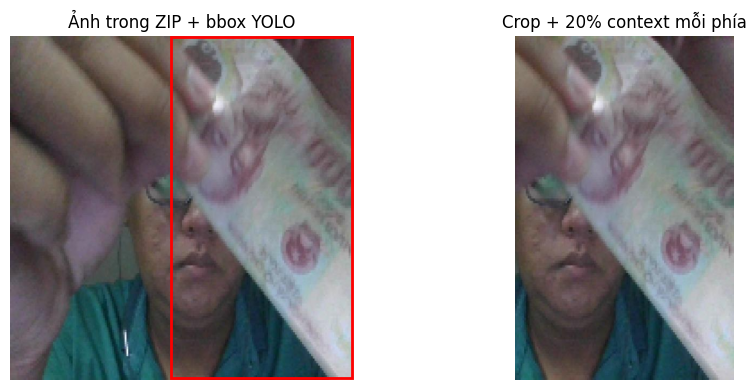

In [40]:
# Minh họa một ảnh có bbox không phủ hết ảnh.
demo = next(row for row in selected.to_dict("records") if row["bbox_short_side_px"] < 400)
with Image.open(io.BytesIO(archive.read(demo["member"]))) as image:
    image = image.convert("RGB")
    crop_box = context_box(demo["bbox"], image.width, image.height)
    demo_crop = image.crop(crop_box)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(image)
left, top, right, bottom = demo["bbox"]
axes[0].add_patch(plt.Rectangle((left, top), right-left, bottom-top, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("Ảnh trong ZIP + bbox YOLO")
axes[1].imshow(demo_crop)
axes[1].set_title("Crop + 20% context mỗi phía")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 7. Lưu ảnh crop và manifest

Cắt ảnh RGB và lưu PNG trong split `train`, theo nhãn cuối cùng. Tạo manifest để ghi nguồn, nhãn và tọa độ.

In [41]:
DATA_OUT = OUTPUT / "BANKNOTES_377"
output_rows = []
rows_to_save = selected.sort_values(["final_label", "path_order"])
for row in rows_to_save.to_dict("records"):
    raw_bytes = archive.read(row["member"])
    with Image.open(io.BytesIO(raw_bytes)) as image:
        image = image.convert("RGB")
        crop_box = context_box(row["bbox"], image.width, image.height)
        crop = image.crop(crop_box)
    relative_path = f"train/{row['final_label']}/BANKNOTES_{row['source_name']}.png"
    target = DATA_OUT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    crop.save(target, format="PNG", optimize=False)
    output_rows.append((row, raw_bytes, relative_path, crop_box, crop, target))

In [42]:
manifest_rows = []
for row, raw_bytes, relative_path, crop_box, crop, target in output_rows:
    manifest_rows.append({
        "relative_path": relative_path, "split": "train", "denomination": row["final_label"],
        "dataset_id": "banknotes_v2", "source_name": row["source_name"],
        "source_archive_member": row["member"], "annotation_member": row["annotation_member"],
        "raw_label": row["raw_label"], "capture_group": row["capture_group"],
        "source_image_sha256": hashlib.sha256(raw_bytes).hexdigest(),
        "bbox_x1": row["bbox"][0], "bbox_y1": row["bbox"][1],
        "bbox_x2": row["bbox"][2], "bbox_y2": row["bbox"][3],
        "bbox_short_side_px": row["bbox_short_side_px"],
        "crop_x1": crop_box[0], "crop_y1": crop_box[1],
        "crop_x2": crop_box[2], "crop_y2": crop_box[3],
        "crop_width": crop.width, "crop_height": crop.height,
        "final_crop_sha256": hashlib.sha256(target.read_bytes()).hexdigest(),
    })
result = pd.DataFrame(manifest_rows)
result.to_csv(DATA_OUT / "manifest.csv", index=False)
assert len(result) == 377
assert result.groupby("denomination").size().to_dict() == EXPECTED_COUNTS
assert len(list(DATA_OUT.rglob("*.png"))) == 377


In [43]:
with ZipFile(OUTPUT / "BANKNOTES_377.zip", "w", ZIP_DEFLATED) as package:
    for path in sorted(DATA_OUT.rglob("*")):
        if path.is_file():
            package.write(path, path.relative_to(DATA_OUT).as_posix())
archive.close()
print("Xuất 377 ảnh:", DATA_OUT)
print("ZIP:", OUTPUT / "BANKNOTES_377.zip")


Xuất 377 ảnh: C:\CS231_BANKNOTES_FROM_RAW\single_notebook_runs\20261025_181449_021158\BANKNOTES_377
ZIP: C:\CS231_BANKNOTES_FROM_RAW\single_notebook_runs\20261025_181449_021158\BANKNOTES_377.zip
